<div dir="rtl">

# الحلقة 1: يعني إيه Reinforcement Learning؟

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/mmmohamedaaashraf/deep-rl-arabic/blob/main/ep01-what-is-rl/ep01_what_is_rl.ipynb)

**سلسلة Deep RL بالعربي**، مبنية على [كورس Hugging Face Deep RL](https://huggingface.co/learn/deep-rl-course) (Unit 1).
فيديو الحلقة على يوتيوب: [Mohamed Ashraf](https://www.youtube.com/@MmmohamedAaashraf)

في النوتبوك دي هنشوف الـ RL loop بعينينا: agent بيلعب LunarLander بشكل عشوائي، ونطبع الـ state والـ action والـ reward في كل خطوة.
وفي الآخر هنشوف نفس المركبة بعد ما اتدربت بـ PPO وهي بتهبط صح.

**على Colab:** دوس على الزرار اللي فوق، وبعدين `Runtime > Run all`.
</div>

<div dir="rtl">

## 1) التجهيز
الخلية دي بتسطّب المكتبات لو انت على Colab، ومش بتعمل حاجة لو عندك كل حاجة متسطبة.
</div>

In [1]:
import sys, subprocess
if "google.colab" in sys.modules:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "swig"], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "gymnasium[box2d]", "stable-baselines3", "imageio", "imageio-ffmpeg"], check=True)

import numpy as np, matplotlib.pyplot as plt, imageio, gymnasium as gym
from IPython.display import Video
print("gymnasium", gym.__version__)

gymnasium 1.4.0


<div dir="rtl">

## 2) الـ Environment: مركبة لازم تنزل على القمر
الـ state عبارة عن 8 أرقام (مكان المركبة، سرعتها، زاويتها، والرجلين لمسوا الأرض ولا لأ)، وقدامنا 4 actions.
</div>

In [2]:
env = gym.make("LunarLander-v3", render_mode="rgb_array")
print("Observation space:", env.observation_space.shape)   # 8 numbers describe the state
print("Action space     :", env.action_space)               # 4 possible actions

Observation space: (8,)
Action space     : Discrete(4)


<div dir="rtl">

## 3) الـ RL loop: state ← action ← reward ← next state
الـ agent هنا عشوائي: بيختار action بالصدفة، من غير أي تعلم.
</div>

In [3]:
ACTIONS = ["do nothing", "fire left", "fire main", "fire right"]

state, info = env.reset(seed=42)
env.action_space.seed(42)
frames, rewards, log = [env.render()], [], []
done = False
while not done:
    action = env.action_space.sample()                       # random agent (no learning yet)
    next_state, reward, terminated, truncated, info = env.step(action)
    log.append((state.round(2), ACTIONS[action], round(float(reward), 2)))
    rewards.append(float(reward))
    frames.append(env.render())
    state, done = next_state, terminated or truncated

for t, (s, a, r) in enumerate(log[:5]):
    print(f"t={t} | x={s[0]:+.2f} y={s[1]:+.2f} | action={a:<10} | reward={r:+.2f}")
print("...")
print(f"Episode ended after {len(rewards)} steps")
print(f"Last reward  : {rewards[-1]:+.1f}")
print(f"Total return : {sum(rewards):+.1f}")

t=0 | x=+0.00 y=+1.42 | action=do nothing | reward=+1.14
t=1 | x=+0.00 y=+1.42 | action=fire right | reward=+0.23
t=2 | x=+0.01 y=+1.43 | action=fire main  | reward=-3.65
t=3 | x=+0.01 y=+1.44 | action=fire left  | reward=+1.53
t=4 | x=+0.01 y=+1.44 | action=fire left  | reward=+2.03
...
Episode ended after 123 steps
Last reward  : -100.0
Total return : -351.2


<div dir="rtl">

## 4) نتفرج على الحلقة
</div>

In [4]:
imageio.mimsave("ep01_random_agent.mp4", frames, fps=50, macro_block_size=8)
Video("ep01_random_agent.mp4", embed=True, width=480)

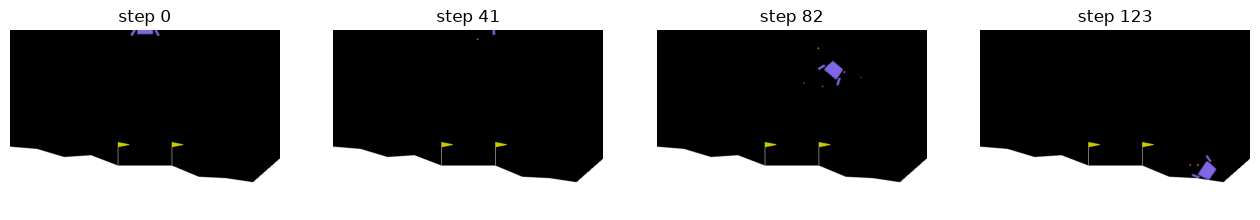

In [5]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3))
for ax, i in zip(axes, np.linspace(0, len(frames) - 1, 4).astype(int)):
    ax.imshow(frames[i]); ax.set_title(f"step {i}"); ax.axis("off")
plt.show()

<div dir="rtl">

## 5) الـ reward في كل خطوة، والمجموع التراكمي
آخر خطوة فيها 100- لأن المركبة وقعت.
</div>

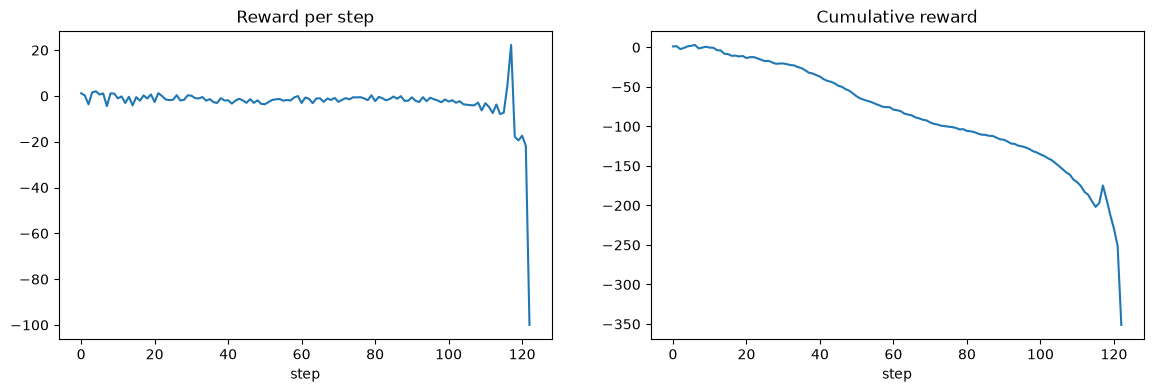

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].plot(rewards); ax[0].set_title("Reward per step"); ax[0].set_xlabel("step")
ax[1].plot(np.cumsum(rewards)); ax[1].set_title("Cumulative reward"); ax[1].set_xlabel("step")
plt.show()

<div dir="rtl">

## 6) الـ agent العشوائي في 100 حلقة
يمكن كان حظه وحش؟ نجربه 100 مرة ونشوف.
</div>

Mean return : -191.0 +/- 106.9
Best episode: 51.4
Episodes above 200 (= solved): 0 / 100


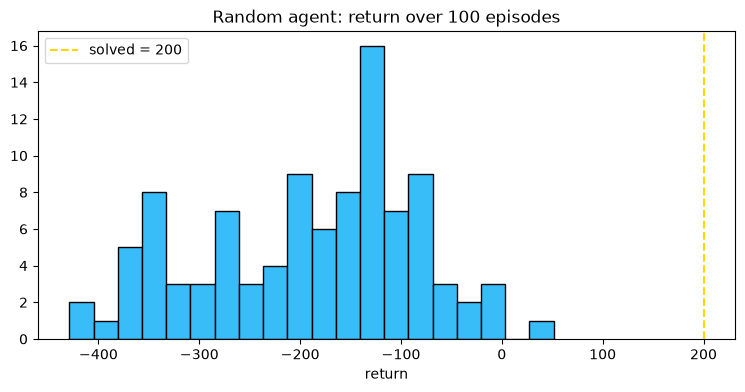

In [7]:
returns = []
for ep in range(100):
    s, _ = env.reset(seed=ep)
    env.action_space.seed(ep)
    total, done = 0.0, False
    while not done:
        s, r, term, trunc, _ = env.step(env.action_space.sample())
        total += r; done = term or trunc
    returns.append(total)
returns = np.array(returns)
print(f"Mean return : {returns.mean():.1f} +/- {returns.std():.1f}")
print(f"Best episode: {returns.max():.1f}")
print(f"Episodes above 200 (= solved): {(returns >= 200).sum()} / 100")

plt.figure(figsize=(9, 4))
plt.hist(returns, bins=20, color="#38BDF8", edgecolor="black")
plt.axvline(200, color="gold", ls="--", label="solved = 200")
plt.title("Random agent: return over 100 episodes"); plt.xlabel("return"); plt.legend()
plt.show()
env.close()

<div dir="rtl">

## 7) بونص: نفس المركبة بعد التدريب
ده agent اتدرب بـ PPO مليون خطوة (الكود في `train_ppo.py`، وهنشرحه بالتفصيل في حلقة PPO).
هنا بنحمّل الموديل المتدرب ونتفرج عليه.
</div>

In [8]:
import os, urllib.request
from stable_baselines3 import PPO
from stable_baselines3.common.evaluation import evaluate_policy
from stable_baselines3.common.monitor import Monitor

MODEL = "ppo-LunarLander-v3.zip"
if not os.path.exists(MODEL):
    urllib.request.urlretrieve("https://github.com/mmmohamedaaashraf/deep-rl-arabic/raw/main/ep01-what-is-rl/" + MODEL, MODEL)
model = PPO.load(MODEL)

mean, std = evaluate_policy(model, Monitor(gym.make("LunarLander-v3")), n_eval_episodes=10, deterministic=True)
print(f"Trained agent: mean return over 10 episodes = {mean:.1f} +/- {std:.1f}")

env = gym.make("LunarLander-v3", render_mode="rgb_array")
obs, _ = env.reset(seed=44)
frames, total, done = [env.render()], 0.0, False
while not done:
    action, _ = model.predict(obs, deterministic=True)
    obs, r, term, trunc, _ = env.step(action)
    total += r; frames.append(env.render()); done = term or trunc
env.close()
print(f"This landing: return = {total:+.1f}")
imageio.mimsave("ppo_landing.mp4", frames, fps=50, macro_block_size=8)
Video("ppo_landing.mp4", embed=True, width=480)

Trained agent: mean return over 10 episodes = 224.1 +/- 20.1


This landing: return = +269.6


<div dir="rtl">

## الخلاصة
- الـ agent بياخد state، يختار action، والـ environment يرجعله reward و state جديدة.
- الـ agent العشوائي بيقع تقريبًا كل مرة، والـ agent المتدرب بيهبط صح.
- **الحلقة الجاية:** ليه هدف الـ agent هو **مجموع** الـ rewards؟ ويعني إيه discounting؟

عندك سؤال أو رأي؟ اكتبه في كومنت على الفيديو أو ابعتهولي:
[LinkedIn](https://www.linkedin.com/in/mohamed-ashraf0) · [Facebook](https://www.facebook.com/MohamedAshrafIN) · [YouTube](https://www.youtube.com/@MmmohamedAaashraf)
</div>